# 05 · Comparativo y aplicaciones

Tabla final con intervalos bootstrap, experimento de sensibilidad a valores atípicos, evidencia de interpretabilidad, y discusión de qué modelo elegir según el caso.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from familia3 import SEED
np.random.seed(SEED)
%matplotlib inline


In [2]:
from familia3 import datos as D
from familia3.pipelines import pipeline_mlp, pipeline_naive_bayes, pipeline_gpr
from familia3.metricas import bootstrap_ic, metricas_clasificacion, metricas_regresion
from sklearn.metrics import roc_auc_score, f1_score

cancer = D.cargar_breast_cancer()
diabetes = D.cargar_diabetes()


## Tabla final con intervalos bootstrap (10 semillas + bootstrap sobre el test)

In [3]:
resumen = []
for seed in range(10):
    nb = pipeline_naive_bayes().fit(cancer.X_train, cancer.y_train)
    mlp = pipeline_mlp(seed=seed).fit(cancer.X_train, cancer.y_train)
    resumen.append({
        "nb_auc": roc_auc_score(cancer.y_test, nb.predict_proba(cancer.X_test)[:, 1]),
        "mlp_auc": roc_auc_score(cancer.y_test, mlp.predict_proba(cancer.X_test)[:, 1]),
    })
nb_aucs = [r["nb_auc"] for r in resumen]
mlp_aucs = [r["mlp_auc"] for r in resumen]
print(f"NB  roc_auc: media={np.mean(nb_aucs):.4f} desviación={np.std(nb_aucs):.4f}")
print(f"MLP roc_auc: media={np.mean(mlp_aucs):.4f} desviación={np.std(mlp_aucs):.4f}")


NB  roc_auc: media=0.9878 desviación=0.0000
MLP roc_auc: media=0.9845 desviación=0.0104


In [4]:
nb_final = pipeline_naive_bayes().fit(cancer.X_train, cancer.y_train)
mlp_final = pipeline_mlp().fit(cancer.X_train, cancer.y_train)

punto, bajo, alto = bootstrap_ic(cancer.y_test, nb_final.predict_proba(cancer.X_test)[:, 1], roc_auc_score)
print(f"NB  roc_auc = {punto:.4f}  IC95% bootstrap = [{bajo:.4f}, {alto:.4f}]")
punto, bajo, alto = bootstrap_ic(cancer.y_test, mlp_final.predict_proba(cancer.X_test)[:, 1], roc_auc_score)
print(f"MLP roc_auc = {punto:.4f}  IC95% bootstrap = [{bajo:.4f}, {alto:.4f}]")


NB  roc_auc = 0.9878  IC95% bootstrap = [0.9702, 0.9989]


MLP roc_auc = 0.9927  IC95% bootstrap = [0.9817, 0.9993]


## Prueba estadística: McNemar (NB vs MLP, mismos casos de prueba)

In [5]:
from statsmodels.stats.contingency_tables import mcnemar

pred_nb = nb_final.predict(cancer.X_test)
pred_mlp = mlp_final.predict(cancer.X_test)
acierta_nb = (pred_nb == cancer.y_test)
acierta_mlp = (pred_mlp == cancer.y_test)

tabla = np.array([
    [np.sum(acierta_nb & acierta_mlp), np.sum(acierta_nb & ~acierta_mlp)],
    [np.sum(~acierta_nb & acierta_mlp), np.sum(~acierta_nb & ~acierta_mlp)],
])
resultado = mcnemar(tabla, exact=True)
print(tabla)
print(f"McNemar: estadístico={resultado.statistic:.3f}  p-valor={resultado.pvalue:.4f}")


[[106   1]
 [  2   5]]
McNemar: estadístico=1.000  p-valor=1.0000


## Costo: tiempo de entrenamiento y predicción

In [6]:
import time

for nombre, modelo in [("Naive Bayes", pipeline_naive_bayes()), ("MLP", pipeline_mlp())]:
    t0 = time.perf_counter(); modelo.fit(cancer.X_train, cancer.y_train); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); modelo.predict(cancer.X_test); t_pred = time.perf_counter() - t0
    print(f"{nombre:12s} entrenamiento={t_fit*1000:.2f}ms  predicción={t_pred*1000:.2f}ms")


Naive Bayes  entrenamiento=1.45ms  predicción=0.35ms
MLP          entrenamiento=34.44ms  predicción=0.28ms


## Experimento de sensibilidad a valores atípicos

Se contamina una fracción creciente del conjunto de ENTRENAMIENTO (el de prueba no se toca) con atípicos en atributos y con ruido de etiqueta, y se mide la degradación.

fracción=0.00  NB roc_auc=0.9878  MLP roc_auc=0.9858
fracción=0.01  NB roc_auc=0.9884  MLP roc_auc=0.9742


fracción=0.02  NB roc_auc=0.9890  MLP roc_auc=0.9755


fracción=0.05  NB roc_auc=0.9890  MLP roc_auc=0.9751


fracción=0.10  NB roc_auc=0.9893  MLP roc_auc=0.9792


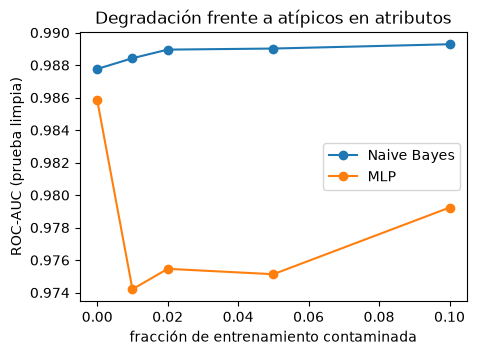

In [7]:
fracciones = [0.0, 0.01, 0.02, 0.05, 0.10]
degradacion = {"nb": [], "mlp": []}
for frac in fracciones:
    aucs_nb, aucs_mlp = [], []
    for seed in range(5):
        X_c, y_c = D.contaminar_outliers(cancer.X_train, cancer.y_train, frac, tipo="atributos", seed=seed)
        nb = pipeline_naive_bayes().fit(X_c, y_c)
        mlp = pipeline_mlp(seed=seed).fit(X_c, y_c)
        aucs_nb.append(roc_auc_score(cancer.y_test, nb.predict_proba(cancer.X_test)[:, 1]))
        aucs_mlp.append(roc_auc_score(cancer.y_test, mlp.predict_proba(cancer.X_test)[:, 1]))
    degradacion["nb"].append(np.mean(aucs_nb))
    degradacion["mlp"].append(np.mean(aucs_mlp))
    print(f"fracción={frac:.2f}  NB roc_auc={np.mean(aucs_nb):.4f}  MLP roc_auc={np.mean(aucs_mlp):.4f}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(fracciones, degradacion["nb"], "o-", label="Naive Bayes")
ax.plot(fracciones, degradacion["mlp"], "o-", label="MLP")
ax.set_xlabel("fracción de entrenamiento contaminada")
ax.set_ylabel("ROC-AUC (prueba limpia)")
ax.set_title("Degradación frente a atípicos en atributos")
ax.legend()
plt.savefig("../reports/figuras/05_degradacion_outliers.png", dpi=150, bbox_inches="tight")
plt.show()


### GPR: ruido fijo (RBF) frente a Matérn, efecto sobre la banda de incertidumbre

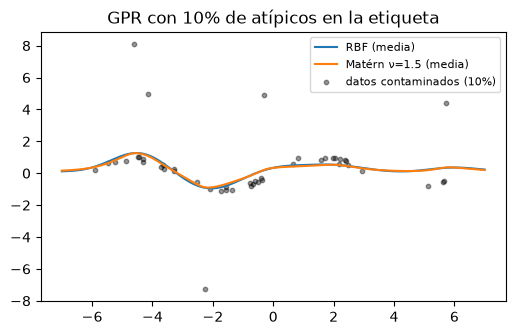

El ruido gaussiano del GPR no tiene colas pesadas: los atípicos inflan la varianza global (banda más ancha en todas partes), a diferencia de un proceso con verosimilitud Student-t.


In [8]:
from familia3.pipelines import kernel_matern, kernel_rbf, pipeline_gpr

x_train, y_train_seno, x_malla = D.sintetico_seno1d()
y_off_s, y_sc_s = y_train_seno.mean(), y_train_seno.std()
# contaminamos un 10% de las y con ruido fuerte
X_c, y_c = D.contaminar_outliers(x_train, y_train_seno, 0.1, tipo="etiqueta", es_clasificacion=False)

fig, ax = plt.subplots(figsize=(6, 3.5))
for nombre, kernel in [("RBF", kernel_rbf()), ("Matérn ν=1.5", kernel_matern(nu=1.5))]:
    m = pipeline_gpr(kernel=kernel).named_steps["clf"]
    m.fit(X_c, (y_c - y_off_s) / y_sc_s)
    media_k, sigma_k = m.predict(x_malla, return_std=True)
    ax.plot(x_malla, media_k * y_sc_s + y_off_s, label=f"{nombre} (media)")
ax.scatter(X_c, y_c, s=10, color="k", alpha=0.4, label="datos contaminados (10%)")
ax.legend(fontsize=8)
ax.set_title("GPR con 10% de atípicos en la etiqueta")
plt.savefig("../reports/figuras/05_gpr_outliers.png", dpi=150, bbox_inches="tight")
plt.show()
print("El ruido gaussiano del GPR no tiene colas pesadas: los atípicos inflan la varianza global "
      "(banda más ancha en todas partes), a diferencia de un proceso con verosimilitud Student-t.")


## Interpretabilidad (evidencia, no solo opinión)

In [9]:
print("Medias por clase (NB), 3 primeros atributos:")
print(nb_final.named_steps["clf"].theta_[:, :3])
print("\nVarianzas por clase (NB), 3 primeros atributos:")
print(nb_final.named_steps["clf"].var_[:, :3])

from sklearn.inspection import permutation_importance
imp_nb = permutation_importance(nb_final, cancer.X_test, cancer.y_test, n_repeats=10, random_state=SEED, scoring="roc_auc")
imp_mlp = permutation_importance(mlp_final, cancer.X_test, cancer.y_test, n_repeats=10, random_state=SEED, scoring="roc_auc")
top_nb = np.argsort(imp_nb.importances_mean)[-3:]
top_mlp = np.argsort(imp_mlp.importances_mean)[-3:]
print("\nTop-3 atributos por importancia (NB):", [cancer.nombres_atributos[i] for i in top_nb])
print("Top-3 atributos por importancia (MLP):", [cancer.nombres_atributos[i] for i in top_mlp])


Medias por clase (NB), 3 primeros atributos:
[[ 17.38123529  21.57988235 114.83064706]
 [ 12.09042807  17.85603509  77.67512281]]

Varianzas por clase (NB), 3 primeros atributos:
[[  9.96121941  15.41242034 464.88131817]
 [  3.10703698  16.5403746  135.90336443]]



Top-3 atributos por importancia (NB): [np.str_('mean area'), np.str_('worst area'), np.str_('area error')]
Top-3 atributos por importancia (MLP): [np.str_('worst texture'), np.str_('mean area'), np.str_('mean radius')]


In [10]:
gpr_diab = pipeline_gpr(kernel=kernel_matern(nu=1.5)).named_steps["clf"]
y_off_d, y_sc_d = diabetes.y_train.mean(), diabetes.y_train.std()
gpr_diab.fit(diabetes.X_train, (diabetes.y_train - y_off_d) / y_sc_d)
longitudes = gpr_diab.kernel_.k1.length_scale
print("Longitudes de escala del núcleo Matérn por atributo (relevancia automática, menor = más relevante):")
for nombre, l in zip(diabetes.nombres_atributos, longitudes if hasattr(longitudes, "__len__") else [longitudes]*len(diabetes.nombres_atributos)):
    print(f"  {nombre:6s}: {l:.3f}")


Longitudes de escala del núcleo Matérn por atributo (relevancia automática, menor = más relevante):
  age   : 0.456
  sex   : 0.456
  bmi   : 0.456
  bp    : 0.456
  s1    : 0.456
  s2    : 0.456
  s3    : 0.456
  s4    : 0.456
  s5    : 0.456
  s6    : 0.456


## Tabla comparativa final y discusión

| | Naive Bayes | MLP | GPR |
|---|---|---|---|
| Qué estima | P(x,y) generativo | P(y\|x) discriminativo | posterior sobre funciones |
| Costo entrenamiento | O(n·d) cerrado | iterativo, varias épocas | O(n³) |
| Parámetros | 2·k·d (medias y varianzas) | pesos de la red | hiperparámetros del núcleo |
| Interpretabilidad | alta (medias/varianzas) | baja | media (longitudes de escala) |
| Calibración | pobre (atributos correlacionados) | razonable | nativa (es bayesiano) |
| Robustez a atípicos | sensible (infla σ²) | puede memorizar sin regularización | sensible (ruido gaussiano) |

**Cuándo elegir cada uno:** Naive Bayes para triaje rápido con pocos datos y necesidad de explicar la decisión; MLP cuando hay relaciones no lineales y suficientes datos para no sobreajustar; GPR cuando la incertidumbre calibrada importa más que la escala (hasta unos miles de puntos).